Running AlievPanfilov on (400, 200) Grid:   0%|          | 0/2000 [00:00<?, ?it/s]

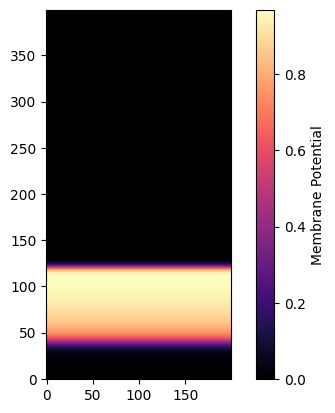

In [ ]:
import matplotlib.pyplot as plt

import finitewave as fw
import numpy as np

n, m = 400, 200


stim_prepacing = fw.StimSingleCell(dt=0.01)
stim_prepacing.add_stim(n_beats=30, cycle_length=30., curr_value=10., duration=.5)

# create model object and set up parameters
cardiac_model = fw.AlievPanfilov()
cardiac_model.prepacing(stim_prepacing)
cardiac_model.a = 0.2 * np.ones((n, m), dtype=np.float32)


tissue = fw.CardiacTissue((n, m), dr=0.25)

# set up stimulation parameters:
stim_sequence = fw.StimSequence()
stim_sequence.add_stim(fw.StimVoltageCoord(time=0, volt_value=1,
                                           x_min=0, x_max=5,
                                           y_min=0, y_max=m))

# create model object and set up parameters:
simulation = fw.CardiacSimulation(dt=0.01, t_max=20, backend="mlx")
simulation.cardiac_model = cardiac_model
simulation.cardiac_tissue = tissue
simulation.stim_sequence = stim_sequence

# run the model:
simulation.run(sync_step=10)

u_clean = simulation.cardiac_model.u

# show the potential map at the end of calculations:
plt.figure()
plt.imshow(u_clean, cmap='magma', origin="lower")
plt.colorbar(label="Membrane Potential")
plt.show()

Running Courtemanche on (400, 200) Grid:   0%|          | 0/8000 [00:00<?, ?it/s]

Running Courtemanche on (400, 200) Grid:   0%|          | 0/11000 [00:00<?, ?it/s]

Running Courtemanche on (400, 200) Grid:   0%|          | 0/19000 [00:00<?, ?it/s]

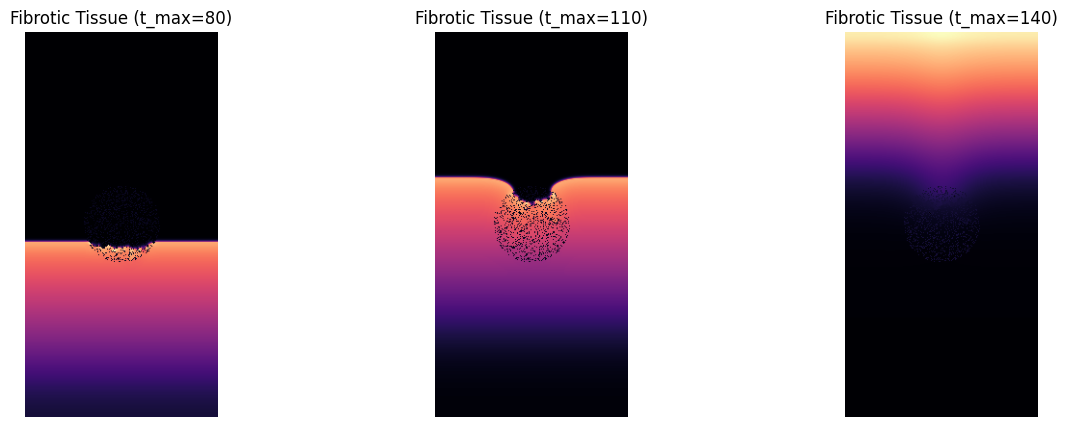

In [34]:
import matplotlib.pyplot as plt

import finitewave as fw
import numpy as np

n, m = 400, 200

# create a circular mesh with a radius of 100 and center at (200, 100)
indices = np.indices((n, m))
center = np.array([n // 2, m // 2])
radius = 40
mask = np.linalg.norm(indices - center[:, None, None], axis=0) <= radius
mask &= (np.random.rand(*tissue.mesh.shape) < 0.2)

u_fibro_collection = []
for t_max in [80, 110, 190]:
    # create model object and set up parameters
    cardiac_model = fw.Courtemanche()
    cardiac_model.prepacing(stim_prepacing)
    cardiac_model.set_parameters(remodeled_params)

    tissue = fw.CardiacTissue((n, m), dr=0.25)
    tissue.mesh[mask] = 2  # add some fibrosis

    # set up stimulation parameters:
    stim_sequence = fw.StimSequence()
    stim_sequence.add_stim(fw.StimVoltageCoord(time=0, volt_value=1,
                                            x_min=0, x_max=5,
                                            y_min=0, y_max=m))

    # create model object and set up parameters:
    simulation = fw.CardiacSimulation(dt=0.01, t_max=t_max, backend="mlx")
    simulation.cardiac_model = cardiac_model
    simulation.cardiac_tissue = tissue
    simulation.stim_sequence = stim_sequence

    # run the model:
    simulation.run(sync_step=10)
    u_fibro = simulation.cardiac_model.u
    u_fibro_collection.append(u_fibro)

# show the potential map at the end of calculations:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for i, u_fibro in enumerate(u_fibro_collection):
    axs[i].imshow(u_fibro, cmap='magma', origin="lower")
    axs[i].set_title(f"Fibrotic Tissue (t_max={80 + i * 30})")
    axs[i].axis('off')
plt.show()

Running Courtemanche on (400, 200) Grid:   0%|          | 0/14000 [00:00<?, ?it/s]

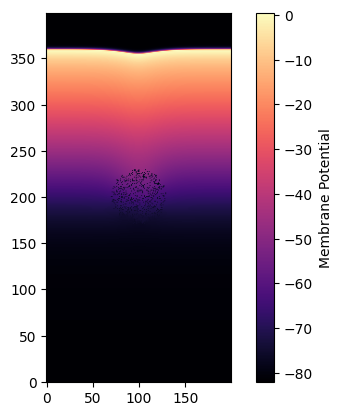

In [21]:
import matplotlib.pyplot as plt

import finitewave as fw
import numpy as np

# create model object and set up parameters
cardiac_model = fw.Courtemanche()
cardiac_model.prepacing(stim_prepacing)
cardiac_model.set_parameters(remodeled_params)

n, m = 400, 200

# create a circular mesh with a radius of 100 and center at (200, 100)
indices = np.indices((n, m))
center = np.array([n // 2, m // 2])
radius = 40
mask = np.linalg.norm(indices - center[:, None, None], axis=0) <= radius

tissue = fw.CardiacTissue((n, m), dr=0.25)
tissue.conductivity = np.ones_like(tissue.mesh, dtype=float)
tissue.conductivity[mask] = 0.8

# set up stimulation parameters:
stim_sequence = fw.StimSequence()
stim_sequence.add_stim(fw.StimVoltageCoord(time=0, volt_value=1,
                                           x_min=0, x_max=5,
                                           y_min=0, y_max=m))

# create model object and set up parameters:
simulation = fw.CardiacSimulation(dt=0.01, t_max=140, backend="mlx")
simulation.cardiac_model = cardiac_model
simulation.cardiac_tissue = tissue
simulation.stim_sequence = stim_sequence

# run the model:
simulation.run(sync_step=10)

u_cond = simulation.cardiac_model.u

# show the potential map at the end of calculations:
plt.figure()
plt.imshow(u, cmap='magma', origin="lower")
plt.colorbar(label="Membrane Potential")
plt.show()

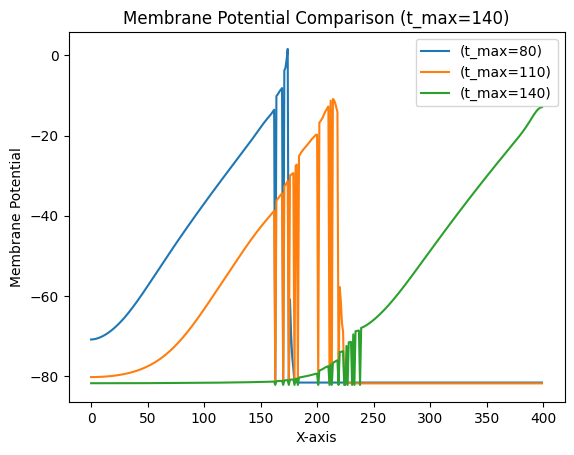

In [35]:
for i, u_fibro in enumerate(u_fibro_collection):
    u_fibro[mask] = u_fibro.min()
    plt.plot(u_fibro[:, m// 2], label=f'(t_max={80 + i * 30})')
    plt.title(f"Membrane Potential Comparison (t_max={80 + i * 30})")
    plt.xlabel("X-axis")
    plt.ylabel("Membrane Potential")
plt.legend()
plt.show()

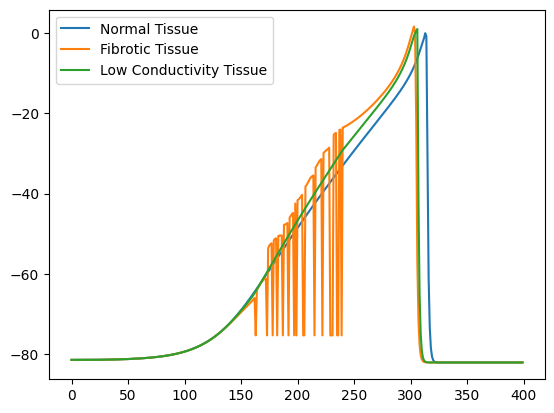

In [24]:
plt.plot(u_clean[:, m// 2], label='Normal Tissue')
plt.plot(u_fibro[:, m// 2], label='Fibrotic Tissue')
plt.plot(u_cond[:, m// 2], label='Low Conductivity Tissue')
plt.legend()
plt.show()